# PROJEK JARINGAN SYARAF TIRUAN (JST)
## Prediksi Intensitas Kebakaran Hutan (Fire Radiative Power / FRP) di Kalimantan Menggunakan Data Riil Satelit NASA FIRMS (VIIRS 375m)

### Konteks & Latar Belakang Masalah
Kebakaran hutan dan lahan (karhutla) di wilayah Kalimantan menimbulkan dampak ekologis, kerugian ekonomi, gangguan kesehatan lintas wilayah, serta ancaman keselamatan bagi personel pemadaman di lapangan (seperti insiden helikopter water-bombing di Seruyan, Kalteng).

Satelit pemantau bumi seperti **Suomi-NPP** dengan sensor **VIIRS (Visible Infrared Imaging Radiometer Suite)** mendeteksi anomali termal aktif pada permukaan bumi. Besaran energi termal yang dilepaskan diukur melalui **Fire Radiative Power (FRP)** dalam satuan MegaWatt (MW). FRP menjadi indikator utama keganasan kobaran api.

Dalam projek ini, dibangun model **Jaringan Syaraf Tiruan (JST) - Multilayer Perceptron (MLP)** menggunakan **PyTorch** dengan akselerasi **CUDA GPU** untuk mengestimasi dan memprediksi intensitas FRP berdasarkan koordinat spasial, resolusi citra sensor, radiansi kanal termal, status siang/malam, dan tingkat kepercayaan deteksi.

In [3]:
# 1. Import Library Utama & Konfigurasi Komputasi
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Reproducibility seed
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Deteksi Device Komputasi (GPU NVIDIA CUDA atau CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch Version  : {torch.__version__}')
print(f'Komputasi Device : {device.type.upper()}')
if device.type == 'cuda':
    print(f'Nama GPU         : {torch.cuda.get_device_name(0)}')
    print(f'Alokasi Memori   : {torch.cuda.get_device_properties(0).total_memory / 1024**3:.2f} GB')

PyTorch Version  : 2.12.0.dev20260408+cu128
Komputasi Device : CUDA
Nama GPU         : NVIDIA GeForce RTX 5050 Laptop GPU
Alokasi Memori   : 7.96 GB


### 2. Memuat Dataset Riil NASA FIRMS (Kalimantan)

In [4]:
csv_file = 'data_karhutla_kalimantan_cleaned.csv'
df = pd.read_csv(csv_file)

print(f'Ukuran dataset: {df.shape[0]:,} baris data dan {df.shape[1]} kolom.')
df.head()

Ukuran dataset: 35,826 baris data dan 9 kolom.


,latitude,longitude,bright_ti4,scan,track,bright_ti5,is_day,confidence_score,frp
0,-2.97735,110.81212,335.33,0.41,0.37,303.09,1,2,3.33
1,-2.97506,110.80424,367.00,0.41,0.37,307.10,1,3,8.11
2,-2.97393,110.81159,334.47,0.41,0.37,306.52,1,1,3.33
3,-2.97108,110.80739,336.21,0.41,0.37,307.31,1,2,5.56
4,-2.96323,110.90434,341.82,0.41,0.37,302.79,1,2,3.25


### 3. Eksplorasi Data & Matriks Korelasi Fitur

Statistik Deskriptif Fitur:


,count,mean,std,min,25%,50%,75%,max
latitude,35826.0,-2.372889,1.013729,-4.17222,-2.946455,-2.685350,-2.103135,4.46876
longitude,35826.0,113.544240,1.777740,109.28479,112.151180,113.613165,114.490482,119.49319
bright_ti4,35826.0,326.947861,18.402483,208.00000,309.330000,330.140000,340.890000,367.00000
scan,35826.0,0.452620,0.078329,0.32000,0.400000,0.430000,0.490000,0.80000
track,35826.0,0.460747,0.111197,0.36000,0.380000,0.400000,0.540000,0.78000
bright_ti5,35826.0,292.515541,9.175385,241.17000,289.310000,294.200000,297.460000,359.34000
is_day,35826.0,0.404901,0.490880,0.00000,0.000000,0.000000,1.000000,1.00000
confidence_score,35826.0,2.005750,0.244568,1.00000,2.000000,2.000000,2.000000,3.00000
frp,35826.0,7.360030,12.354437,0.15000,1.840000,3.690000,7.880000,319.51000


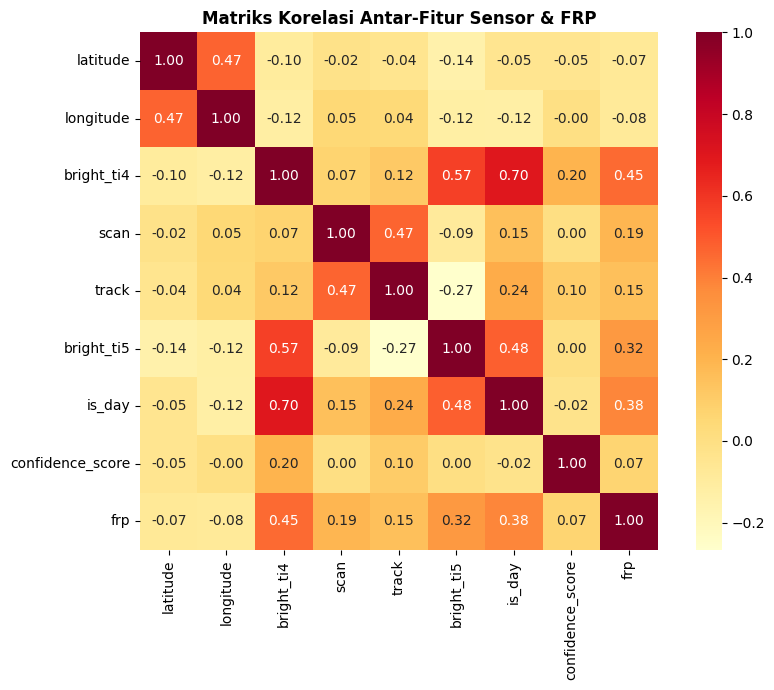

In [5]:
# Statistik deskriptif seluruh fitur
print('Statistik Deskriptif Fitur:')
display(df.describe().T)

# Visualisasi Matriks Korelasi (Heatmap)
plt.figure(figsize=(9, 7))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='YlOrRd', cbar=True, square=True)
plt.title('Matriks Korelasi Antar-Fitur Sensor & FRP', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 4. Preprocessing: Feature Selection, Splitting, & Normalisasi Z-Score
- **Fitur Masukan ($X$)**: `latitude`, `longitude`, `bright_ti4`, `scan`, `track`, `bright_ti5`, `is_day`, `confidence_score`
- **Target Keluaran ($y$)**: `frp` (Fire Radiative Power - MW)
- **Data Splitting**: 80% Data Pelatihan & Validasi, 20% Data Pengujian Independen (*Hold-out Test Set*)
- **Normalisasi**: `StandardScaler` ($z = \frac{x - \mu}{\sigma}$) diaplikasikan agar gradien backpropagation stabil dan konvergen cepat.

In [6]:
features = ['latitude', 'longitude', 'bright_ti4', 'scan', 'track', 'bright_ti5', 'is_day', 'confidence_score']
target = 'frp'

X = df[features].values
y = df[target].values

# 1. Split Train & Test (80% : 20%)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Split Train menjadi Train (80% dari full) & Validation (20% dari full)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

# 3. Standarisasi Fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# 4. Konversi ke PyTorch Tensor & PyTorch DataLoader
batch_size = 64

train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
)
val_dataset = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print(f'Jumlah Data Latih (Train) : {len(X_train):,} sampel')
print(f'Jumlah Data Validasi (Val): {len(X_val):,} sampel')
print(f'Jumlah Data Uji (Test)    : {len(X_test):,} sampel')

Jumlah Data Latih (Train) : 22,928 sampel
Jumlah Data Validasi (Val): 5,732 sampel
Jumlah Data Uji (Test)    : 7,166 sampel


### 5. Arsitektur Jaringan Syaraf Tiruan (Deep Multilayer Perceptron)

Desain Lapisan JST:
1. **Input Layer**: 8 Neuron masukan sesuai dimensi fitur sensor.
2. **Hidden Layer 1**: 128 Neuron, Aktivasi `ReLU`, Dropout `0.2` (mencegah ko-adaptasi bobot & overfitting).
3. **Hidden Layer 2**: 64 Neuron, Aktivasi `ReLU`, Dropout `0.1`.
4. **Hidden Layer 3**: 32 Neuron, Aktivasi `ReLU`.
5. **Output Layer**: 1 Neuron dengan aktivasi `Linear` (estimasi nilai kontinu daya termal api FRP).

In [7]:
class KarhutlaJST(nn.Module):
    def __init__(self, input_dim):
        super(KarhutlaJST, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        
    def forward(self, x):
        return self.network(x)

model = KarhutlaJST(input_dim=X_train_scaled.shape[1]).to(device)
print(model)

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal Parameter JST yang Dilatih: {total_params:,} bobot & bias.')

KarhutlaJST(
  (network): Sequential(
    (0): Linear(in_features=8, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)

Total Parameter JST yang Dilatih: 11,521 bobot & bias.


### 6. Proses Pelatihan Model JST (Backpropagation & Validasi per Epoch)
- **Fungsi Kerugian (Loss Function)**: Mean Squared Error (MSE)
- **Optimasi**: Adam Optimizer (`learning_rate = 0.001`)
- **Jumlah Epoch**: 30 Epochs

In [8]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 30
history = {'train_loss': [], 'val_loss': []}

print('Memulai proses pelatihan model JST...')
for epoch in range(1, epochs + 1):
    # Fase Pelatihan
    model.train()
    running_train_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        predictions = model(batch_x)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * batch_x.size(0)
        
    epoch_train_loss = running_train_loss / len(X_train)
    
    # Fase Validasi
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_x, batch_y in val_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            preds = model(batch_x)
            v_loss = criterion(preds, batch_y)
            running_val_loss += v_loss.item() * batch_x.size(0)
            
    epoch_val_loss = running_val_loss / len(X_val)
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    
    if epoch % 5 == 0 or epoch == 1:
        print(f'Epoch [{epoch:02d}/{epochs:02d}] | Train Loss (MSE): {epoch_train_loss:.4f} | Val Loss (MSE): {epoch_val_loss:.4f}')

print('Pelatihan JST selesai dengan sukses!')

Memulai proses pelatihan model JST...
Epoch [01/30] | Train Loss (MSE): 122.5494 | Val Loss (MSE): 111.4359
Epoch [05/30] | Train Loss (MSE): 98.8548 | Val Loss (MSE): 95.8097
Epoch [10/30] | Train Loss (MSE): 90.0062 | Val Loss (MSE): 93.7681
Epoch [15/30] | Train Loss (MSE): 88.0168 | Val Loss (MSE): 96.1169
Epoch [20/30] | Train Loss (MSE): 87.3755 | Val Loss (MSE): 89.8001
Epoch [25/30] | Train Loss (MSE): 86.3978 | Val Loss (MSE): 90.5288
Epoch [30/30] | Train Loss (MSE): 84.8219 | Val Loss (MSE): 91.4233
Pelatihan JST selesai dengan sukses!


### 7. Evaluasi Model pada Data Uji Independen (Hold-out Test Set)
Evaluasi dilakukan menggunakan metrik:
1. **MSE (Mean Squared Error)**
2. **RMSE (Root Mean Squared Error)** dalam satuan asli MegaWatt
3. **MAE (Mean Absolute Error)**
4. **$R^2$ Score (Koefisien Determinasi)**

In [9]:
model.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
    y_pred = model(X_test_tensor).cpu().numpy().flatten()

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

eval_df = pd.DataFrame({
    'Metrik': ['Mean Squared Error (MSE)', 'Root Mean Squared Error (RMSE)', 'Mean Absolute Error (MAE)', 'R-squared (R2 Score)'],
    'Nilai': [f'{mse:.4f}', f'{rmse:.4f} MW', f'{mae:.4f} MW', f'{r2:.4f}']
})

print('HASIL EVALUASI MODEL JST PADA DATA UJI:')
display(eval_df)

HASIL EVALUASI MODEL JST PADA DATA UJI:


,Metrik,Nilai
0,Mean Squared Error (MSE),73.2752
1,Root Mean Squared Error (RMSE),8.5601 MW
2,Mean Absolute Error (MAE),3.5324 MW
3,R-squared (R2 Score),0.4658


### 8. Visualisasi Hasil Pembelajaran & Prediksi vs Aktual

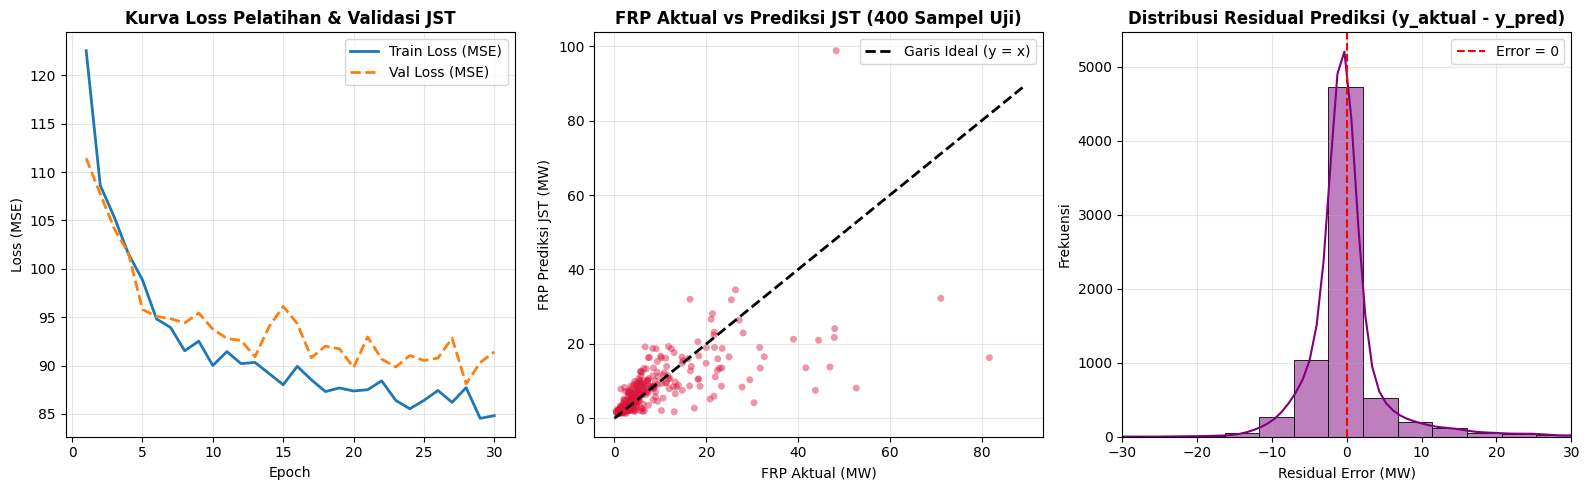

Grafik evaluasi berhasil disimpan ke: hasil_evaluasi_jst.png


In [10]:
plt.figure(figsize=(16, 5))

# 1. Kurva Penurunan Loss Pelatihan dan Validasi
plt.subplot(1, 3, 1)
plt.plot(range(1, epochs + 1), history['train_loss'], label='Train Loss (MSE)', color='tab:blue', lw=2)
plt.plot(range(1, epochs + 1), history['val_loss'], label='Val Loss (MSE)', color='tab:orange', lw=2, linestyle='--')
plt.title('Kurva Loss Pelatihan & Validasi JST', fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Scatter Plot FRP Aktual vs Prediksi JST
plt.subplot(1, 3, 2)
sample_n = 400
plt.scatter(y_test[:sample_n], y_pred[:sample_n], alpha=0.45, color='crimson', edgecolors='none', s=25)
max_val = max(y_test[:sample_n].max(), y_pred[:sample_n].max()) * 0.9
plt.plot([0, max_val], [0, max_val], '--k', lw=2, label='Garis Ideal (y = x)')
plt.title(f'FRP Aktual vs Prediksi JST ({sample_n} Sampel Uji)', fontweight='bold')
plt.xlabel('FRP Aktual (MW)')
plt.ylabel('FRP Prediksi JST (MW)')
plt.legend()
plt.grid(True, alpha=0.3)

# 3. Distribusi Error (Residuals)
residuals = y_test - y_pred
plt.subplot(1, 3, 3)
sns.histplot(residuals, bins=40, kde=True, color='purple')
plt.axvline(0, color='red', linestyle='--', label='Error = 0')
plt.xlim(-30, 30)
plt.title('Distribusi Residual Prediksi (y_aktual - y_pred)', fontweight='bold')
plt.xlabel('Residual Error (MW)')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('hasil_evaluasi_jst.png', dpi=300)
plt.show()
print('Grafik evaluasi berhasil disimpan ke: hasil_evaluasi_jst.png')

### 9. Simulasi Inferensi: Estimasi Keganasan Titik Api Baru untuk Mitigasi Lapangan
Sistem rekomendasi alokasi unit pemadam berdasarkan prediksi besaran daya termal api (MW).

In [11]:
# Simulasi titik api baru di Kalimantan Tengah
sample_hotspots = pd.DataFrame([
    {'lokasi': 'Katingan (Hutan Gambut Pekat)', 'latitude': -2.05, 'longitude': 113.35, 'bright_ti4': 365.2, 'scan': 0.40, 'track': 0.38, 'bright_ti5': 304.5, 'is_day': 1, 'confidence_score': 3},
    {'lokasi': 'Seruyan (Dekat Pemukiman)', 'latitude': -2.52, 'longitude': 112.21, 'bright_ti4': 342.1, 'scan': 0.48, 'track': 0.42, 'bright_ti5': 298.0, 'is_day': 1, 'confidence_score': 2},
    {'lokasi': 'Ketapang (Titik Api Malam Hari)', 'latitude': -1.82, 'longitude': 110.15, 'bright_ti4': 324.6, 'scan': 0.55, 'track': 0.45, 'bright_ti5': 291.3, 'is_day': 0, 'confidence_score': 1}
])

X_sim = sample_hotspots[features].values
X_sim_scaled = scaler.transform(X_sim)

model.eval()
with torch.no_grad():
    sim_tensor = torch.tensor(X_sim_scaled, dtype=torch.float32).to(device)
    pred_frp = model(sim_tensor).cpu().numpy().flatten()

sample_hotspots['Prediksi FRP (MW)'] = np.round(pred_frp, 2)

def kategori_bahaya(frp_val):
    if frp_val >= 20.0:
        return 'CRITICAL / TINGGI (Prioritaskan Water Bombing Helikopter)'
    elif frp_val >= 8.0:
        return 'MODERATE / SEDANG (Tim Manggala Agni Darat)'
    else:
        return 'LOW / RINGAN (Pemantauan Satelit Berkala)'

sample_hotspots['Status & Rekomendasi Mitigasi'] = sample_hotspots['Prediksi FRP (MW)'].apply(kategori_bahaya)

display(sample_hotspots[['lokasi', 'latitude', 'longitude', 'bright_ti4', 'Prediksi FRP (MW)', 'Status & Rekomendasi Mitigasi']])

,lokasi,latitude,longitude,bright_ti4,Prediksi FRP (MW),Status & Rekomendasi Mitigasi
0,Katingan (Hutan Gambut Pekat),-2.05,113.35,365.2,17.10,MODERATE / SEDANG (Tim Manggala Agni Darat)
1,Seruyan (Dekat Pemukiman),-2.52,112.21,342.1,12.64,MODERATE / SEDANG (Tim Manggala Agni Darat)
2,Ketapang (Titik Api Malam Hari),-1.82,110.15,324.6,7.34,LOW / RINGAN (Pemantauan Satelit Berkala)
